## Table of Contents

#### Part I: Research Question

A1. [Research Question](#A1.-Research-Question)

A2. [Defined Goal](#A2.-Defined-Goal)

#### Part II: Technique Justification

B1. [Explanation of Clustering Technique](#B1.-Explanation-of-Clustering-Technique)

B2. [Summary of Technique Assumptions](#B2.-Summary-of-Method-Assumptions)

B3. [Packages and Libraries](#B3.-Packages-and-Libraries)

#### Part III: Data Preparation

C1. [Data Preprocessing](#C1.-Data-Preprocessing)

C2. [Dataset Variables](#C2.-Dataset-Variables)

C3. [Steps for Analysis](#C3.-Steps-for-Analysis)

C4. [Cleaned Dataset](#C4.-Cleaned-Dataset)

#### Part IV: Analysis

D1. [Output and Intermediate Calculations](#D2.-Output-and-Intermediate-Calculations)

D2. [Code Execution](#D3.-Code-Execution)

#### Part V: Data Summary and Implications

E1. [Quality of Clustering Technique](#E1.-Quality-of-Clustering-Technique)

E2. [Results and Implications](#E2.-Results-and-Implications)

E3. [Limitations](#E3.-Limitations)

E4. [Course of Action](#E4.-Course-of-Action)

#### Part VI: Sources


G. [Sources of Third-Party Code](#G.-Sources-of-Third-Party-Code)

H. [Sources](#H.-Sources)

### Part I: Research Question

#### A1. Research Question

The purpose of this data mining report will be to apply k-means clustering to the customer population represented in the "churn" dataset, in order to identify trends and assign labels within this population based on bandwidth usage and monthly payments. The question that the report will seek to answer is, how is this population segmented based on the relationship between each customer's bandwidth usage and their monthly fees?

#### A2. Defined Goal

The goal of this analysis will be to determine customer segmentation based on bandwidth usage and monthly payments. The analysis will use k-means clustering, an unsupervised machine learning algorithm, to apply labels to customers and thereby group them into clusters based on these two continuous variables.

### Part II: Technique Justification

#### B1. Explanation of Clustering Technique

K-means clustering is an unsupervised machine learning method that can be used to organize unlabelled data into clusters, based on the similarity of observations to other obserations. "Unsupervised" ML methods are those that train models using unlabeled data, meaning that the input data has not already been categorized; the method identifies patterns based solely on the values of the data, rather than through associating the data to predetermined labels. (GeeksForGeeks, 2025) K-means clustering achieves this by performing a series of steps:

- A series of points, referred to as "centroids," are randomly scattered among the data;
- Each observation within the dataset is assigned to its closest centroid;
- The centroid's placement within the dataset is updated to be the average of all observations assigned to it;
- The above steps are repeated until the centroid has found a static place within the data and no longer moves.

The end result of the above steps is that all observations within the dataset have now been labeled and assigned into one of the clusters created by the steps above; these clusters are inherently defined by the similarities of the observations contained within them. The number of centroids used in this process is referred to by the variable k, which is defined at the beginning of this process, and from which the name "k means clustering" is derived. (GeeksforGeeks, 2025)

For this analysis, I will be using k means clustering to categorize customers from the churn dataset according to their bandwidth usage and monthly payments. The expected result will be the creation of a number of clusters into which these customers will be assigned, providing a clearer picture of customer segmentation based on these metrics.

#### B2. Summary of Technique Assumptions

K means clustering assumes that observations with shared or similar traits exist in proximity to one another; for example, when data is plotted out in a graph, observations that have shared features will have shorter distances between each other when compared to observations that are dissimilar. K means clusters data together based on proximity, and assumes that observations within these clusters can be said to be similar.

#### B3. Packages and Libraries

For this analysis, I'll be using Python, which is a free and open-source programming language that is widely used for analytics. Python has access to a large number of analytic libraries that are specifically designed for all types of machine learning work, including k means clustering. I'll be using many of these libraries, including Pandas, NumPy, Scikit-Learn, and Matplotlib.

Pandas is a Python library that allows for the importation, and subsequent manipulation, of tabluar data. Pandas stores this data in a unique object type called "dataframes", which organize data into columns and rows. In this way, dataframes have some similarities with spreadsheets, or relational database tables. (Pandas Documentation, 2024)

Scikit-Learn is a machine learning package that features the ability to create and apply a large number of machine learning models, including specific functionality for implementing k means clustering. It also has some pre-processing capabilities that will be used here, including a scaler to help normalize the data used to build the k means model.

Matplotlib is a visualization package that allows for the creation of various charts and graphs, such as scatterplots. This analysis will use matplotlib to help visualize the churn data, as well as the clusters determined during application of the k means model.

NumPy is a scientific computing package that provides support for arrays, in the form of the ndarray object. (NumPy Documentation, 2024) This analysis will make some use of NumPy arrays, such as when creating the k means model; NumPy will also be use for some simple calcuations, such as creating interquartile ranges during initial data cleaning to help identify outliers.

### Part III: Data Preparation

#### C1. Data Preprocessing

For this analysis, one of the data preprocessing goals will be to standardize the data by scaling it; this will be accomplished using the Scikit-Learn StandardScaler function. Scaling is commonly required for many machine learning algorithms, and is useful in k means clustering. (Scikit-learn Documentation, 2025) Because k means is a distance-based estimator which labels observations based on their distance from one another, the scale of the data can strongly affect the outcome of the clustering; scaling the data will prevent the magnitude of the variables from causing bias in the model. (Sharma, 2019).

#### C2. Dataset Variables

This analysis will seek to group customers into clusters based on two metrics: "MonthlyCharge", or the amount they pay each month for their telecommunications services, and "Bandwidth_GB_Year", which is the yearly amount of data used by these customers. Both of these variables are numeric continuous variables.

#### C3. Steps for Analysis

The code used below to clean the input Churn dataset is partially re-used from my earlier projects in this degree program. As the same Churn dataset was used in that assessment, the code is capable of performing similar data cleaning tasks for this analysis

This code performs the following functions:

1. Imports the packages necessary to complete the data cleaning task: pandas and numpy.
2. Finds complete duplicate records within the data (that is, records that are complete duplicates of one another across all columns). If complete duplicates are found, the code returns "True"; otherwise it returns a "False."
3. Finds duplicate values that are expected to be unique, based on the definitions provided in the data dictionary for the Churn dataset. These columns are 'Customer_id' and 'Interaction'. The code returns a True or False for each of these columns, depending on whether or not dupes are found.
4. Searchings for missing/null columns across all records, and then returns a list of columns that have missing values. If no missing data is found, it will return the message "No missing data found."
5. Evaluates all columns that should be confined to values of "Yes" or "No", and prints a list of columns that contain values other than these two. The columns being evaluated are 'Churn', 'Techie', 'Port_modem', 'Tablet', 'Phone', 'Multiple', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', and 'PaperlessBilling'. If no invalid values are found, the code prints the message "No invalid boolean values found."
6. Evaluates all categorical columns to ensure that they only contain valid values as defined in the data dictionary. The columns evaluated are 'Gender', 'Marital', 'Area', 'Contract', 'InternetService', and 'PaymentMethod'. The code will print out a list of columns that have invalid values; if none are found, it will return "No invalid categorical values found".
7. Identifies and removes outliers in continuous variables based on a comparison to interquartile ranges.
7. Removes the columns that are unnecessary for this analysis - Customer_id, Interaction, UID, City, State, County, Zip, Lat, Lng, TimeZone, Job, and Items 1 through 8.

In [1]:
# Initial cleaning of dataset

# Import necessary packages
import pandas as pd
import numpy as np

# Import the dataset
churnfile = pd.read_csv('../data/churn_clean.csv',index_col=0, keep_default_na=False, na_values=['NA'])  # 'None' is a valid InternetService value

# Data quality check: Find complete dupes
churnfile_compldupes = churnfile.duplicated()
print("Complete dupes: " + str(churnfile_compldupes.any()))

# Data quality check: Look for dupes on columns that should be unique
uniquecols = ['Customer_id','Interaction']
for cols in (uniquecols):
    churnfile_uniqdupes = churnfile.duplicated(subset=cols, keep=False)
    print("Dupes in column " + cols + ": " + str(churnfile_uniqdupes.any()))

# Data quality check: Look for missing data
missingcols = []
for cols in churnfile:
    if ((churnfile[cols].isnull().sum()) > 0):
        missingcols.append(cols)
if len(missingcols) > 0:
    print("Columns that are missing data: ")
    print(missingcols)
else:
    print("No missing data found")

# Data quality check: Find non-boolean values in boolean vars
boolvars = ['Churn','Techie','Port_modem','Tablet','Phone','Multiple',
            'OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport',
            'StreamingTV','StreamingMovies','PaperlessBilling']
badbools = []
for col in boolvars:
    if churnfile[col][~churnfile[col].isin(["Yes","No"])].any() == True:
        badbools.append(col)
if len(badbools) > 0:
    print("Boolean columns that have out-of-range values: ")
    print(badbools)
else:
    print("No invalid boolean values found")        
    
# Data quality check: Find invalid categorical values
rangecols = {"Gender":['Male','Female','Nonbinary'],
             "Marital":['Married','Separated','Divorced','Never Married','Widowed'],
             "Area":["Rural","Urban","Suburban"],
             "Contract":["One year","Two Year","Month-to-month"],
             "InternetService":["Fiber Optic","DSL","None"],
             "PaymentMethod":["Bank Transfer(automatic)","Credit Card (automatic)",
                              "Electronic Check","Mailed Check"]
            }
badrange = []
for col, val in rangecols.items():
    if churnfile[col][~churnfile[col].isin(val)].any() == True:
        badrange.append(col)
if len(badrange) > 0:
    print("Categorical columns that have invalid values: ")
    print(badrange)
else:
    print("No invalid categorical values found")
    
# Find and remove outliers
# Bandwidth_GB_Year
# Outage_sec_perweek
# Population
# Tenure

for col in ['Bandwidth_GB_Year','Outage_sec_perweek','Population','Tenure']:
    Q3 = np.percentile(churnfile[col], 75)
    Q1 = np.percentile(churnfile[col], 25)
    
    IQR = (Q3-Q1)
    
    lowerlimit = Q1-(1.5*IQR)
    upperlimit = Q3+(1.5*IQR)
    
    churnfile.drop(churnfile[churnfile[col] > upperlimit].index, inplace=True)
    churnfile.drop(churnfile[churnfile[col] < lowerlimit].index, inplace=True)
    
    print("Outliers removed for " + col)
    
# Drop extraneous variables from the file
churnfile.drop(["Customer_id","Interaction","UID","City","State","County","Zip","Lat","Lng","TimeZone",
                                 "Job","Item1","Item2","Item3","Item4","Item5","Item6","Item7","Item8"], axis=1, inplace=True)



Complete dupes: False
Dupes in column Customer_id: False
Dupes in column Interaction: False
No missing data found
No invalid boolean values found
No invalid categorical values found
Outliers removed for Bandwidth_GB_Year
Outliers removed for Outage_sec_perweek
Outliers removed for Population
Outliers removed for Tenure


At this point the dataset can be said to have been cleaned successfully. The code has verified that there are no duplicate records; that no duplicate values exist within unique columns; there are no missing or null values; there are no invalid values within boolean or categorical columns; and, all outliers have been removed from numeric continuous variables.

The next step will be to set aside the necessary variables for this analysis - MonthlyCharge and Bandwidth_GB_Year - into their own NumPy array; this will act as the input when creating the k means model.

In [2]:
# Set aside variables of interest into new dataset

churn_points = np.array(churnfile[['MonthlyCharge','Bandwidth_GB_Year']])
churn_points

array([[ 172.455519 ,  904.5361102],
       [ 242.632554 ,  800.9827661],
       [ 159.947583 , 2054.706961 ],
       ...,
       [ 159.9794   , 6511.252601 ],
       [ 169.9741   , 4159.305799 ],
       [ 217.484    , 5857.586167 ]], shape=(8999, 2))

Before using this data to generate the k means model, it is important to scale the data to ensure that it's evaluated properly. Scaling ensures that the magnitued of a given variable will not negatively impact the analysis by eclipsing the impact of other variables. (Sharma, 2019) 

In [3]:
# Scale the data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
churn_scaled = scaler.fit_transform(churn_points)
churn_scaled

array([[-0.00999883, -1.14381566],
       [ 1.62021417, -1.19122255],
       [-0.30055827, -0.61726555],
       ...,
       [-0.29981916,  1.42294837],
       [-0.06764221,  0.34622326],
       [ 1.03601309,  1.1236988 ]], shape=(8999, 2))

#### C4. Cleaned Dataset

In [4]:
churnfile.to_csv('churnfile_prepared.csv', index=False)

churn_points_pd = pd.DataFrame(churn_points)
churn_points_pd.to_csv('churnfile_kmeans_scaled.csv', index=False)

A copy of the cleaned data has been attached as the comma-delimited file, "churnfile_prepared.csv". Additionally, a copy of the scaled data that will be used to create the k means model has been attached as a comma-delimited file, "churnfile_kmeans_scaled.csv".

### Part IV: Analysis

The input data has now been successfully cleaned and prepared for use in creating the k means model. We can now plot these variables in a scatterplot, to help visualize the relationship between them, as well as the associated distribution of customers.

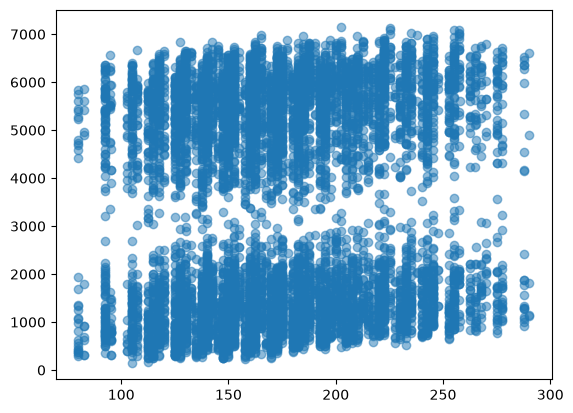

In [5]:
# Plot these variables on a scatterplot to visualize the relationship between them

import matplotlib.pyplot as plt

x_vals = churn_points[:,0]
y_vals = churn_points[:,1]

plt.scatter(x_vals,y_vals,alpha=0.5)
plt.show()

At first glance, the customers seem to be distributed into two groups: a group of high bandwidth use, and a group of low bandwidth use. However, there is the potential that the k means model may reveal additional clusters and more accurate customer segmentation.

We should now proceed with building the initial k means model. The initial model will use a placeholder value of 3 for k; after creating this initial model, additional steps will be taken to determine the best value to use for k.

In [6]:
# Build the initial KMeans model
# Import necessary packages for Kmeans clustering
from sklearn.cluster import KMeans

# Assign model, fit data, assign labels to new data
model = KMeans(n_clusters=3, n_init=10, random_state=1337)

model.fit(churn_scaled)

labels = model.predict(churn_scaled)

Now that the model is created, we can inspect the labels to determine how the population is distributed amongst the clusters.

In [7]:
# Inspect the distribution of labels generated by the kmeans model
churn_scaled_labels = pd.Series(model.labels_).value_counts().sort_index()
churn_scaled_labels

0    2149
1    3501
2    3349
Name: count, dtype: int64

#### D1. Output and Intermediate Calculations

The initial model has been created using a value of 3 for k, meaning that 3 centroids and thus 3 clusters have been created. However, this is just a placeholder value - there is a strong possibility that a different value for k will return improved results. The goal here is to create a model that can provide accurate insights into customer segmentation without getting too far into the gritty details of the dataset; the model should return a number of clusters that are useful for the analysis, but not so many as to become meaningless. 

One metric that can be used to determine the optimal value of k is by the "elbow method", so called because it involves the creation of a line plot that tracks the value of inertia against rising values for k. Inertia is defined as the sum of squared distances between each observation and its assigned centroid; in a sense, it can be interpreted as a metric that tracks the "tightness" of the defined clusters, and by extension, how accurately each cluster represents its component observations. (GeeksforGeeks, 2025)

Below, I will execute a block of code that iteratively generates k means cluster models for values of k between 2 and 8; it then uses matplotlib to create a line graph that plots inertia for each level of k.

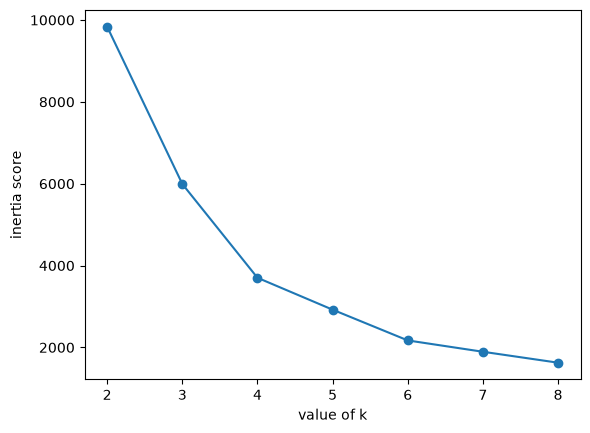

In [8]:
# Determine optimal number of clusters
# Start with plotting inertia by cluster count
k_count = range(2,9)
inerts = []

for k in k_count:
    # Create a KMeans instance with k clusters: model
    model = KMeans(n_clusters=k, n_init=10, random_state=1337)

    # Fit to churn_scaled array
    model.fit(churn_scaled)

    # Append the inertia to the list of inertias
    inerts.append(model.inertia_)

# Plot ks vs inertias
plt.plot(k_count, inerts, '-o')
plt.xlabel('value of k')
plt.ylabel('inertia score')
plt.xticks(k_count)
plt.show()

Common practice with inertia plots such as the one above is to target the "elbow" of the plot - that is, the point at which the value of inertia seems to stablize relative to the value of k - and use this k value for generating the k means model. (GeeksforGeeks, 2025) Above, the so-called "elbow" value seems to be around 4; after this, the amount which inertia seems to decrease as k increases appears to stabilize.

Another method for determining the number of clusters is using the silhouette score; this score measures both how well each observation fits within its cluster, and the distance each observation is from the next-nearest neighboring cluster. In a sense, the silhouette score is a measure of how well a labeled observation "belongs" to its assigned cluster.

[np.float64(0.4664298305696286), np.float64(0.47783300959111535), np.float64(0.48688097378427225), np.float64(0.46447442167504327), np.float64(0.4432765142668908), np.float64(0.4164419359434926), np.float64(0.389327648704926)]


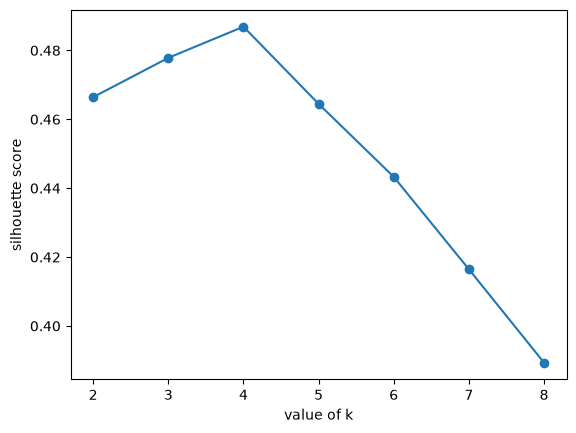

In [9]:
# Import necessary packages for silhouette scores
from sklearn.metrics import silhouette_score

# Determine optimal number of clusters
# Start with plotting inertia by cluster count
k_count = range(2,9)
s_scores = []

for k_val in k_count:
    # Create a KMeans instance with k clusters: model
    model = KMeans(n_clusters=k_val, n_init=10, random_state=1337)

    # Fit to churn_scaled array
    model.fit(churn_scaled)

    # Append the inertia to the list of inertias
    s_scores.append(silhouette_score(churn_scaled, model.labels_))

print(s_scores)

# Plot ks vs inertias
plt.plot(k_count, s_scores, '-o')
plt.xlabel('value of k')
plt.ylabel('silhouette score')
plt.xticks(k_count)
plt.show()

As we can see above, the silhouette score peaks at a value around 0.487 when k=4. This aligns with our earlier evaluation of the model using the "elbow method," which also showed an optimal value of k=4 for this k means model. We can now recreate the model using k=4.

In [10]:
# Rebuild the KMeans model using value of 4 for k

# Assign model, fit data, assign labels to new data
model = KMeans(n_clusters=4, n_init=10, random_state=1337)

model.fit(churn_scaled)

labels = model.predict(churn_scaled)

We can also verify the model's new silhouette score, and then print out the number of observations in each of the four clusters. We can also generate a new scatterplot of all observations using matplotlib, this time with each cluster color-coded, and the centroids for each cluster marked with a red diamond.

In [11]:
# Inspect model's silhouette score
silscore = silhouette_score(churn_scaled, model.labels_)
silscore

np.float64(0.4868809737841916)

In [12]:
# Inspect the distribution of labels generated by the kmeans model
churn_scaled_labels = pd.Series(model.labels_).value_counts().sort_index()
churn_scaled_labels

0    1823
1    2675
2    2702
3    1799
Name: count, dtype: int64

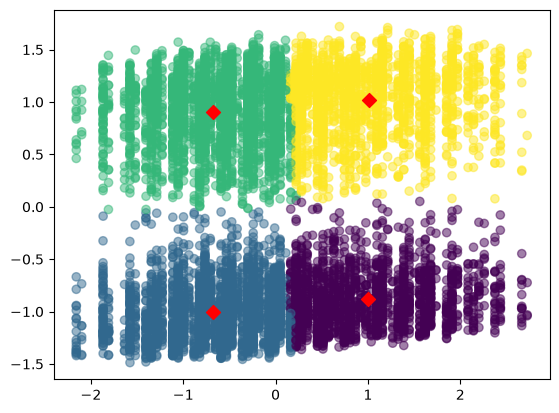

In [13]:
# Print scatterplot of labeled observations/clusters
# Assign the columns of new_points: x_vals and y_vals
x_vals = churn_scaled[:,0]
y_vals = churn_scaled[:,1]

# Generate scatter plot; mark each label with its own color scheme
plt.scatter(x_vals,y_vals,c=labels,alpha=0.5)

# Assign centroids
centrs = model.cluster_centers_
centr_x = centrs[:,0]
centr_y = centrs[:,1]

# Generate scatterplot of centroids
plt.scatter(centr_x,centr_y,marker='D',c='red',s=50)
plt.show()

In [14]:
print(centrs)

[[ 0.99722515 -0.88229817]
 [-0.675693   -1.00037439]
 [-0.67552867  0.90619215]
 [ 1.01158118  1.02070823]]


At this stage, the k means model has been successfully created with four clusters (k=4). The largest clusters seem to be the first and third clusters, which represent low monthly charge/low bandwidth use, and low monthly charge/high bandwidth use, respectively.

#### D2. Code Execution

All annotated code used for this k-means clustering analysis is included above, along with all printed outputs.

### Part V: Data Summary and Implications

#### E1. Quality of Clustering Technique

The quality of the cluster can be determined by evaluating the silhouette score of the model, as below:

In [15]:
# Inspect model's silhouette score
silscore = silhouette_score(churn_scaled, model.labels_)
silscore

np.float64(0.4868809737841916)

The silhouette score of a model can range from -1 to 1, with a higher score indicating better clustering. A score of 1 indicates that the data points fit well within their own clusters and are placed far from incorrect clusters; a score of zero indicates that there may be overlap between clusters; and a score of -1 indicates that data points are placed within the wrong cluster. Typically, a score at or above 0.5 indicates good clustering. (GeeksForGeeks, 2025) 

The silhouette score for this model is 0.487; this is close to, but still below, the 0.5 threshold mentioned above. The quality of clustering in this model can therefore be described as subpar. Although the clusters themselves may be generally useful as high-level descriptions of segmentation within the customer base, there may be some overlap between clusters that could impact the accuracy of labels assigned by the k means model. The model may be considered adequate for creating a generalized understanding of customer segmentation, but may show inaccuracies at the periphery.

#### E2. Results and Implications

The k means clustering analysis reveals that there are four groups into which customers can be sorted:

1. Those with low monthly charges, and low bandwidth usage, accounting for 2675 customers;
2. Those with high monthly charges, and high bandwidth usage, accounting for 1799 customers;
3. Those with low monthly charges, and high bandwidth usage, accounting for 2702 customers;
4. Those with high monthly charges, and low bandwidth usage, accounting for 1823 customers.

The majority of customers seem to fall within the first and third groups, both of which have low monthly charges. Together, these two groups account for around 60% of all customers on the file. The remaining 40% of customers seem to be split more-or-less evenly between the second and fourth groups, both of which have high monthly charges. There seems to be no direct correlation between a customer's bandwidth usage and the size of their monthly bill to the ISP, and generally speaking, more customers have lower monthly charges than higher ones. 

For reference, the cluster observation counts, centroid locations, and scatterplot have been re-printed below.

In [16]:
# Inspect the distribution of labels generated by the kmeans model
churn_scaled_labels = pd.Series(model.labels_).value_counts().sort_index()
churn_scaled_labels

0    1823
1    2675
2    2702
3    1799
Name: count, dtype: int64

In [17]:
print(centrs)

[[ 0.99722515 -0.88229817]
 [-0.675693   -1.00037439]
 [-0.67552867  0.90619215]
 [ 1.01158118  1.02070823]]


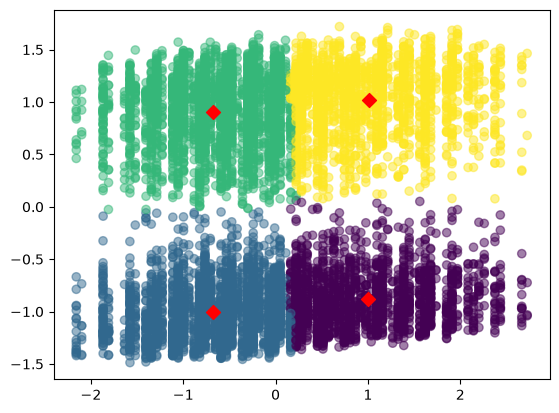

In [18]:
# Print scatterplot of labeled observations/clusters
# Assign the columns of new_points: x_vals and y_vals
x_vals = churn_scaled[:,0]
y_vals = churn_scaled[:,1]

# Generate scatter plot; mark each label with its own color scheme
plt.scatter(x_vals,y_vals,c=labels,alpha=0.5)

# Assign centroids
centrs = model.cluster_centers_
centr_x = centrs[:,0]
centr_y = centrs[:,1]

# Generate scatterplot of centroids
plt.scatter(centr_x,centr_y,marker='D',c='red',s=50)
plt.show()

#### E3. Limitations

As previously discussed in section E1 above, the silhouette score of the k means clustering model indicates that the clustering is middling at best; the model fails to reach a score above 0.5, which would indicate good clustering. The model comes close, with a score of 0.487. This indicates that the model may be useful in identifying general trends in customer segmentation, but is otherwise not a particularly strong model; there may be overlap between clusters, and some observations on the edges of clusters may be incorrectly labeled or misassigned to an incorrect cluster. Stakeholders should be made aware of this fact before utilizing the model to support any sort of decisionmaking. 

#### E4. Course of Action

The ISP should institute a pricing model that more closely tracks bandwidth usage by its customer base. Customers who have higher bandwidth usage place greater strain on the ISP's infrastructure and could contribute to generalized network slowdown for the entire network. Of particular note are the 2702 customers in group 3, who are using more bandwidth than their peers, but have low monthly charges; these customers are utilizing more of the ISP's resources while paying less than other high-bandwidth-use customers. Customers in group 3 should have their monthly bills increased to offset the higher strain they place on the network.

### Part VI: Sources

#### G. Sources of Third-Party Code

Matplotlib Documentation. *matplotlib.pyplot.scatter* Retrieved July 19, 2025 from https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html

Scikit-Learn Documentation. *KMeans*. 2025. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

Scikit-Learn Documentation. *silhouette_score*. 2025. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html

Scikit-Learn Documentation. *StandardScaler*. 2025. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

#### H. Sources

GeeksForGeeks. *Determine the optimal value of K in K-Means Clustering - ML.* July 11, 2025. https://www.geeksforgeeks.org/machine-learning/ml-determine-the-optimal-value-of-k-in-k-means-clustering/

GeeksForGeeks. *Elbow Method for optimal value of k in KMeans.* July 11, 2025. https://www.geeksforgeeks.org/machine-learning/elbow-method-for-optimal-value-of-k-in-kmeans/

GeeksForGeeks. *Supervised and Unsupervised Learning.* July 29, 2025. https://www.geeksforgeeks.org/machine-learning/supervised-unsupervised-learning/

GeeksForGeeks. *What is Silhouette Score?* Jun 23, 2025. https://www.geeksforgeeks.org/machine-learning/what-is-silhouette-score/

Matplotlib Documentation. *Quick Start Guide.* 2024. https://matplotlib.org/stable/users/explain/quick_start.html

NumPy Documentation. *What is NumPy?* 2024. https://numpy.org/doc/2.1/user/whatisnumpy.html#whatisnumpy

Pandas Documentation. *Intro to Pandas.* 2024. https://pandas.pydata.org/docs/getting_started/index.html#intro-to-pandas

Scikit-Learn Documentation. *Getting Started.* 2024. https://scikit-learn.org/stable/getting_started.html

Sharma, Pulkit. *Why is scaling required in KNN and K-Means?* Analytics Vidhya. August 25, 2019. https://medium.com/analytics-vidhya/why-is-scaling-required-in-knn-and-k-means-8129e4d88ed7